# Echo — Groupe 6

Faut-il généraliser les notifications agressives chez Echo ?

## Inspection des données

Les contrôles ci-dessous portent sur les CSV bruts. Aucune correction n'est appliquée.

In [1]:
from pathlib import Path
import pandas as pd

# Le notebook peut être ouvert depuis la racine du dépôt.
data_dir = Path("data")
if not data_dir.is_dir():
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier GrowthModel.")

users_raw = pd.read_csv(data_dir / "users.csv", dtype={"user_id": "string"})
activity_raw = pd.read_csv(data_dir / "weekly_activity.csv", dtype={"user_id": "string"})
spend_raw = pd.read_csv(data_dir / "marketing_spend.csv")
tables = {"users": users_raw, "weekly_activity": activity_raw, "marketing_spend": spend_raw}

for name, table in tables.items():
    print(f"{name} : {len(table):,} lignes, {len(table.columns)} colonnes")
    print(table.dtypes.to_string())
    print()


users : 20,909 lignes, 7 colonnes
user_id                 string[python]
signup_date                     object
acquisition_channel             object
platform                        object
age_bucket                      object
push_variant                    object
shows_followed_week1             int64

weekly_activity : 334,399 lignes, 6 colonnes
user_id                        string[python]
week_start                             object
sessions                                int64
listening_minutes                     float64
ad_impressions                          int64
push_notifications_received             int64

marketing_spend : 17 lignes, 3 colonnes
month         object
channel       object
spend_eur    float64



### Valeurs manquantes et doublons

In [2]:
keys = {"users": ["user_id"], "weekly_activity": ["user_id", "week_start"], "marketing_spend": ["month", "channel"]}
audit_rows = []
for name, table in tables.items():
    distinct_rows = table.drop_duplicates()
    audit_rows.append({
        "table": name,
        "lignes": len(table),
        "copies_exactes": int(table.duplicated().sum()),
        "cles_repetees": int(table.duplicated(keys[name]).sum()),
        "lignes_en_conflit_apres_dedoublonnage": int(distinct_rows.duplicated(keys[name], keep=False).sum()),
    })
    print(f"Valeurs manquantes — {name}")
    print(table.isna().sum().to_string())
    print()
print(pd.DataFrame(audit_rows).to_string(index=False))


Valeurs manquantes — users
user_id                   0
signup_date               0
acquisition_channel       0
platform                  0
age_bucket              660
push_variant              0
shows_followed_week1      0

Valeurs manquantes — weekly_activity
user_id                        0
week_start                     0
sessions                       0
listening_minutes              0
ad_impressions                 0
push_notifications_received    0

Valeurs manquantes — marketing_spend
month        0
channel      0
spend_eur    0

          table  lignes  copies_exactes  cles_repetees  lignes_en_conflit_apres_dedoublonnage
          users   20909             124            124                                      0
weekly_activity  334399            1663           1663                                      0
marketing_spend      17               0              0                                      0


### Dates et catégories

Les dates avec `/` sont lues au format jour/mois/année. Les jours supérieurs à 12 permettent de vérifier cette convention. Les colonnes de contrôle ne remplacent pas les données brutes.

In [3]:
slash_dates = users_raw["signup_date"].str.contains("/", regex=False)
signup_dates = pd.to_datetime(users_raw["signup_date"], format="%Y-%m-%d", errors="coerce")
signup_dates.loc[slash_dates] = pd.to_datetime(users_raw.loc[slash_dates, "signup_date"], format="%d/%m/%Y", errors="coerce")
week_dates = pd.to_datetime(activity_raw["week_start"], format="%Y-%m-%d", errors="coerce")
month_dates = pd.to_datetime(spend_raw["month"], format="%Y-%m-%d", errors="coerce")

print("Dates d'inscription avec / :", int(slash_dates.sum()))
print("Dont jour supérieur à 12 :", int((users_raw.loc[slash_dates, "signup_date"].str[:2].astype(int) > 12).sum()))
print("Dates invalides (inscription, semaine, dépense) :", int(signup_dates.isna().sum()), int(week_dates.isna().sum()), int(month_dates.isna().sum()))
print("Inscriptions :", signup_dates.min().date(), "à", signup_dates.max().date())
print("Activité :", week_dates.min().date(), "à", week_dates.max().date())
print("Semaines ne commençant pas un lundi :", int((week_dates.dt.dayofweek != 0).sum()))
print("Dépenses non datées du premier du mois :", int((month_dates.dt.day != 1).sum()))
for column in ["acquisition_channel", "platform", "age_bucket", "push_variant"]:
    print(f"\n{column}")
    print(users_raw[column].value_counts(dropna=False).to_string())


Dates d'inscription avec / : 314
Dont jour supérieur à 12 : 193
Dates invalides (inscription, semaine, dépense) : 0 0 0
Inscriptions : 2025-01-01 à 2026-06-30
Activité : 2024-12-30 à 2026-06-29
Semaines ne commençant pas un lundi : 0
Dépenses non datées du premier du mois : 0

acquisition_channel
acquisition_channel
paid_social            8950
organic_store          7722
podcast_cross_promo    4237

platform
platform
Android    10496
iOS        10413

age_bucket
age_bucket
25-34    7043
18-24    5964
35-44    4143
45+      3099
NaN       660

push_variant
push_variant
standard           18181
control             1276
aggressive_push     1240
Control              100
AGGRESSIVE_PUSH       58
aggressive            54


### Valeurs numériques

In [4]:
print(activity_raw.select_dtypes("number").describe(percentiles=[0.5, 0.99]).round(2).to_string())
print("\nDurées négatives :", int((activity_raw["listening_minutes"] < 0).sum()))
# Une semaine entière représente 10 080 minutes.
print("Durées supérieures à une semaine :", int((activity_raw["listening_minutes"] > 7 * 24 * 60).sum()))
print("Durées exactement égales à une semaine :", int(activity_raw["listening_minutes"].eq(7 * 24 * 60).sum()))
print("Émissions suivies en semaine 1 :")
print(users_raw["shows_followed_week1"].describe().to_string())
for name, table, columns in [
    ("users", users_raw, ["shows_followed_week1"]),
    ("weekly_activity", activity_raw, ["sessions", "ad_impressions", "push_notifications_received"]),
    ("marketing_spend", spend_raw, ["spend_eur"]),
]:
    print(name, "— valeurs négatives :", (table[columns] < 0).sum().to_dict())


        sessions  listening_minutes  ad_impressions  push_notifications_received
count  334399.00          334399.00       334399.00                    334399.00
mean        3.51             114.53           11.56                         5.26
std         1.84            1737.45            6.88                         6.23
min         1.00              -1.00            1.00                         0.00
50%         3.00              70.10           10.00                         4.00
99%         9.00             264.30           32.00                        36.00
max        21.00           99999.00           82.00                        58.00

Durées négatives : 96
Durées supérieures à une semaine : 100
Durées exactement égales à une semaine : 105
Émissions suivies en semaine 1 :
count    20909.000000
mean         2.211010
std          1.551813
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         12.000000
users — valeurs négatives : {'shows_

### Cohérence entre les fichiers et couverture

Une semaine sans ligne signifie qu'aucune activité n'est enregistrée. Elle ne prouve pas un départ définitif. La première et la dernière semaine peuvent être partielles.

In [5]:
print("Utilisateurs de l'activité absents de users :", len(set(activity_raw["user_id"]) - set(users_raw["user_id"])))
print("Utilisateurs sans activité :", len(set(users_raw["user_id"]) - set(activity_raw["user_id"])))

# Dédupliquer seulement la table de correspondance pour éviter une jointure plusieurs-à-plusieurs.
signup_lookup = pd.DataFrame({"user_id": users_raw["user_id"], "signup_date": signup_dates}).drop_duplicates()
joined = activity_raw[["user_id", "week_start"]].merge(signup_lookup, on="user_id", how="left", validate="many_to_one")
signup_monday = joined["signup_date"] - pd.to_timedelta(joined["signup_date"].dt.dayofweek, unit="D")
print("Activités antérieures à la semaine d'inscription :", int((pd.to_datetime(joined["week_start"]) < signup_monday).sum()))
print("Activités après l'extraction du 30/06/2026 :", int((week_dates > pd.Timestamp("2026-06-30")).sum()))

all_months = pd.date_range("2025-01-01", "2026-06-01", freq="MS")
for channel in spend_raw["channel"].unique():
    recorded_months = month_dates[spend_raw["channel"] == channel]
    print("Mois de dépenses absents pour", channel, ":", all_months.difference(recorded_months).strftime("%Y-%m").tolist())
print("Canaux sans dépenses renseignées :", sorted(set(users_raw["acquisition_channel"]) - set(spend_raw["channel"])))

test_users = pd.DataFrame({"signup_date": signup_dates, "push_variant": users_raw["push_variant"]}).loc[users_raw["push_variant"] != "standard"]
outside_test = ~test_users["signup_date"].between("2026-01-15", "2026-03-15")
print("Lignes de participants inscrits hors de la période du test :", int(outside_test.sum()))


Utilisateurs de l'activité absents de users : 0
Utilisateurs sans activité : 0
Activités antérieures à la semaine d'inscription : 0
Activités après l'extraction du 30/06/2026 : 0
Mois de dépenses absents pour paid_social : ['2025-05']
Canaux sans dépenses renseignées : ['organic_store', 'podcast_cross_promo']
Lignes de participants inscrits hors de la période du test : 0


### Bilan

- 124 copies exactes dans `users` et 1 663 dans `weekly_activity`, sans conflit de valeurs sur les clés.
- 314 dates d'inscription au format jour/mois/année.
- Variantes à harmoniser : `Control`, `AGGRESSIVE_PUSH` et `aggressive`.
- 660 âges absents dans le brut.
- 96 durées négatives et 100 durées de 99 999 minutes dans le brut.
- Dépense `paid_social` de mai 2025 absente. Aucun coût renseigné pour les autres canaux.
- Aucun indicateur fiable ne permet d'identifier des comptes internes ou de test. Aucun compte n'est exclu sur une simple suspicion.

Les règles validées sont appliquées dans la section suivante. Les effectifs changeront après retrait des copies exactes.

## Nettoyage

Choix validés : conserver les utilisateurs sans âge dans la catégorie `inconnu`, remplacer uniquement les durées impossibles par une valeur manquante, et estimer la dépense de mai 2025 entre avril et juin. Les CSV bruts restent intacts. Le journal compte les lignes affectées à chaque étape, dans l'ordre d'exécution.

In [6]:
users = users_raw.copy()
activity = activity_raw.copy()
spend = spend_raw.copy()
cleaning_log = []

def log_rule(table, rule, reason, affected, before, after):
    cleaning_log.append({
        "ordre": len(cleaning_log) + 1,
        "table": table,
        "regle": rule,
        "justification": reason,
        "lignes_affectees": int(affected),
        "lignes_avant": int(before),
        "lignes_apres": int(after),
    })

for name, table in [("users", users), ("weekly_activity", activity)]:
    before = len(table)
    table.drop_duplicates(inplace=True)
    log_rule(name, "Supprimer les copies exactes", "Une observation ne doit être comptée qu'une fois. Aucun conflit sur les clés après dédoublonnage.", before - len(table), before, len(table))

slash = users["signup_date"].str.contains("/", regex=False)
parsed_signup = pd.to_datetime(users["signup_date"], format="%Y-%m-%d", errors="coerce")
parsed_signup.loc[slash] = pd.to_datetime(users.loc[slash, "signup_date"], format="%d/%m/%Y", errors="raise")
assert parsed_signup.notna().all(), "Date d'inscription non reconnue"
users["signup_date"] = parsed_signup
activity["week_start"] = pd.to_datetime(activity["week_start"], format="%Y-%m-%d", errors="raise")
spend["month"] = pd.to_datetime(spend["month"], format="%Y-%m-%d", errors="raise")
log_rule("users", "Uniformiser les dates d'inscription en AAAA-MM-JJ", "Les dates avec / suivent le format jour/mois/année, confirmé par les jours supérieurs à 12.", slash.sum(), len(users), len(users))

variant_mapping = {"Control": "control", "AGGRESSIVE_PUSH": "aggressive_push", "aggressive": "aggressive_push"}
changed_variants = users["push_variant"].isin(variant_mapping)
users["push_variant"] = users["push_variant"].replace(variant_mapping)
log_rule("users", "Harmoniser les libellés des variantes push", "Les trois libellés correspondent aux variantes décrites dans le data pack.", changed_variants.sum(), len(users), len(users))

missing_age = users["age_bucket"].isna()
users["age_bucket"] = users["age_bucket"].fillna("inconnu")
log_rule("users", "Remplacer l'âge absent par inconnu", "Conserver les utilisateurs et ne pas inventer leur âge. Les comparaisons par âge présenteront inconnu séparément.", missing_age.sum(), len(users), len(users))
print("Utilisateurs après nettoyage :", len(users))
print(users["push_variant"].value_counts().to_string())


Utilisateurs après nettoyage : 20785
push_variant
standard           18076
control             1366
aggressive_push     1343


### Durées d'écoute

Une durée négative ou supérieure à 10 080 minutes est impossible. Une durée exactement égale à 10 080 minutes représente sept jours sans pause : on la considère comme suspecte et on l'écarte aussi des calculs d'écoute, sans affirmer qu'elle est nécessairement erronée.

On conserve les autres mesures de la ligne. `listening_minutes_invalid` marque les durées impossibles ; `listening_minutes_suspect` marque celles exactement égales à une semaine. Les deux sont remplacées par une valeur manquante, jamais par zéro. Les valeurs d'origine restent dans les CSV bruts.

In [7]:
negative_minutes = activity["listening_minutes"] < 0
over_week_minutes = activity["listening_minutes"] > 7 * 24 * 60
continuous_week_minutes = activity["listening_minutes"].eq(7 * 24 * 60)
activity["listening_minutes_invalid"] = negative_minutes | over_week_minutes
activity["listening_minutes_suspect"] = continuous_week_minutes
activity.loc[activity["listening_minutes_invalid"] | activity["listening_minutes_suspect"], "listening_minutes"] = float("nan")

log_rule("weekly_activity", "Mettre les durées négatives à manquant", "Garder les sessions, impressions et notifications de la ligne.", negative_minutes.sum(), len(activity), len(activity))
log_rule("weekly_activity", "Mettre les durées supérieures à 10 080 minutes à manquant", "La durée dépasse une semaine entière. Aucun plafonnement ni remplacement par zéro.", over_week_minutes.sum(), len(activity), len(activity))
log_rule("weekly_activity", "Mettre les durées égales à 10 080 minutes à manquant", "Sept jours sans pause : durée suspecte écartée par choix méthodologique. Ligne conservée et identifiée par listening_minutes_suspect.", continuous_week_minutes.sum(), len(activity), len(activity))
print("Lignes d'activité conservées :", len(activity))
print("Durées remplacées par une valeur manquante :", int(activity["listening_minutes"].isna().sum()))


Lignes d'activité conservées : 332736
Durées remplacées par une valeur manquante : 300


### Dépense manquante

La dépense `paid_social` de mai 2025 est estimée à la moyenne d'avril et de juin : `(1 080 + 1 150) / 2 = 1 115 €`. `spend_is_estimated` distingue cette ligne des observations. Les analyses qui l'utilisent, notamment le CAC et le backtest 2025, devront signaler cette estimation. Pour un backtest, cette interpolation ne doit pas servir à prétendre prévoir mai avant de connaître juin. Aucun coût nul n'est supposé pour les autres canaux.

In [8]:
spend["spend_is_estimated"] = False
before = len(spend)
may = pd.Timestamp("2025-05-01")
assert not ((spend["month"] == may) & (spend["channel"] == "paid_social")).any()
neighbors = spend.loc[(spend["channel"] == "paid_social") & spend["month"].isin([pd.Timestamp("2025-04-01"), pd.Timestamp("2025-06-01")]), "spend_eur"]
assert len(neighbors) == 2 and neighbors.notna().all()
estimated_spend = neighbors.mean()
spend = pd.concat([spend, pd.DataFrame([{
    "month": may, "channel": "paid_social", "spend_eur": estimated_spend, "spend_is_estimated": True,
}])], ignore_index=True).sort_values(["month", "channel"]).reset_index(drop=True)
log_rule("marketing_spend", "Ajouter mai 2025 : 1 115 EUR estimés", "Moyenne des dépenses observées d'avril et juin. Ligne identifiée par spend_is_estimated ; montant non observé.", 1, before, len(spend))
print(spend.loc[spend["month"].between("2025-04-01", "2025-06-01")].to_string(index=False))


     month     channel  spend_eur  spend_is_estimated
2025-04-01 paid_social     1080.0               False
2025-05-01 paid_social     1115.0                True
2025-06-01 paid_social     1150.0               False


### Vérification et export

Les fichiers nettoyés sont enregistrés dans `data/clean/`. Le journal est dans `docs/cleaning_log.csv`. Aucun compte n'est supprimé sans indicateur fiable. La semaine du 29 juin 2026 est partielle et devra être traitée comme telle dans les analyses.

In [9]:
# Les clés sont uniques et tous les utilisateurs de l'activité sont connus.
assert users["user_id"].is_unique
assert not activity.duplicated(["user_id", "week_start"]).any()
assert not spend.duplicated(["month", "channel"]).any()
assert activity["user_id"].isin(users["user_id"]).all()
assert users["signup_date"].between("2025-01-01", "2026-06-30").all()
assert users["push_variant"].isin(["standard", "control", "aggressive_push"]).all()
assert users["age_bucket"].isin(["18-24", "25-34", "35-44", "45+", "inconnu"]).all()
assert activity["week_start"].dt.dayofweek.eq(0).all()
assert activity["listening_minutes"].dropna().between(0, 10080, inclusive="left").all()
assert activity["listening_minutes"].isna().equals(activity["listening_minutes_invalid"] | activity["listening_minutes_suspect"])

# Le nettoyage des durées ne modifie pas les autres mesures.
activity_distinct = activity_raw.drop_duplicates()
for column in ["sessions", "ad_impressions", "push_notifications_received"]:
    assert activity[column].equals(activity_distinct[column])
assert len(activity) == len(activity_distinct)
assert len(users) == users_raw["user_id"].nunique()
assert spend["spend_is_estimated"].sum() == 1
assert estimated_spend == 1115
assert spend.loc[~spend["spend_is_estimated"], "spend_eur"].sum() == spend_raw["spend_eur"].sum()

log = pd.DataFrame(cleaning_log)
assert len(users_raw) - len(users) == log.loc[log["table"].eq("users"), "lignes_avant"].iloc[0] - log.loc[log["table"].eq("users"), "lignes_apres"].iloc[-1]
clean_dir = data_dir / "clean"
clean_dir.mkdir(exist_ok=True)
Path("docs").mkdir(exist_ok=True)
for filename, table in [("users.csv", users), ("weekly_activity.csv", activity), ("marketing_spend.csv", spend)]:
    table.to_csv(clean_dir / filename, index=False, date_format="%Y-%m-%d", encoding="utf-8")
log.to_csv("docs/cleaning_log.csv", index=False, encoding="utf-8")
print(log[["ordre", "table", "regle", "lignes_affectees", "lignes_avant", "lignes_apres"]].to_string(index=False))
print("\nVérifications réussies. Fichiers nettoyés et journal enregistrés.")


 ordre           table                                                     regle  lignes_affectees  lignes_avant  lignes_apres
     1           users                              Supprimer les copies exactes               124         20909         20785
     2 weekly_activity                              Supprimer les copies exactes              1663        334399        332736
     3           users         Uniformiser les dates d'inscription en AAAA-MM-JJ               311         20785         20785
     4           users                Harmoniser les libellés des variantes push               211         20785         20785
     5           users                        Remplacer l'âge absent par inconnu               657         20785         20785
     6 weekly_activity                    Mettre les durées négatives à manquant                95        332736        332736
     7 weekly_activity Mettre les durées supérieures à 10 080 minutes à manquant               100        33273

## Diagnostic de croissance

On utilise les fichiers nettoyés. Les semaines sont des semaines calendaires du lundi au dimanche. S0 est la semaine d'inscription, S4 celle qui commence quatre semaines plus tard. Ce ne sont pas des fenêtres individuelles de sept jours. Une activité est une ligne avec au moins une session.

Les comparaisons excluent les horizons qui ne sont pas entièrement observables au 30 juin 2026. Une semaine absente signifie aucune activité enregistrée, pas un départ définitif. Les revenus sont estimés avec le CPM d'environ 9 € indiqué dans le [data pack](docs/Echo%20-%20Project%20data%20pack.pdf).

In [10]:
import matplotlib.pyplot as plt

users = pd.read_csv("data/clean/users.csv", parse_dates=["signup_date"])
activity = pd.read_csv("data/clean/weekly_activity.csv", parse_dates=["week_start"])
spend = pd.read_csv("data/clean/marketing_spend.csv", parse_dates=["month"])
cutoff = pd.Timestamp("2026-06-30")
CPM = 9.0
users["signup_week"] = users["signup_date"] - pd.to_timedelta(users["signup_date"].dt.dayofweek, unit="D")
users["cohort"] = users["signup_date"].dt.to_period("M").astype(str)
activity = activity.merge(users[["user_id", "signup_week", "cohort", "acquisition_channel", "platform", "age_bucket", "push_variant"]], on="user_id", validate="many_to_one")
activity["age_week"] = (activity["week_start"] - activity["signup_week"]).dt.days // 7
activity["ad_revenue_eur"] = activity["ad_impressions"] * CPM / 1000
activity_keys = pd.MultiIndex.from_frame(activity[["user_id", "week_start"]])

def observable(frame, age):
    return frame["signup_week"] + pd.to_timedelta(age * 7 + 6, unit="D") <= cutoff

def returned(frame, age):
    target = frame["signup_week"] + pd.Timedelta(weeks=age)
    return pd.Series(pd.MultiIndex.from_arrays([frame["user_id"], target]).isin(activity_keys), index=frame.index)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
print("Utilisateurs :", len(users), "| Lignes d'activité :", len(activity))


Utilisateurs : 20785 | Lignes d'activité : 332736


### Activation : comparaison des seuils

On cherche un usage répété et une écoute réelle : au moins deux sessions pendant S0, avec 10, 20 ou 30 minutes d'écoute. Cela ne prouve pas l'écoute de deux épisodes.

Une durée manquante reste indéterminée si le nombre de sessions atteint deux. Avec moins de deux sessions, le critère échoue déjà. La comparaison avec S4 utilise les mêmes utilisateurs pour les trois seuils et exclut les suivis incomplets. Il s'agit d'une association descriptive, pas d'un effet causal de l'activation.

In [11]:
first_week = activity[["user_id", "week_start", "sessions", "listening_minutes"]].rename(columns={"week_start": "signup_week"})
activation = users.merge(first_week, on=["user_id", "signup_week"], how="left", validate="one_to_one")
assert activation["sessions"].notna().all(), "Vérifier les inscriptions sans activité S0 avant de les classer."

def activation_status(frame, minutes):
    status = frame["sessions"].ge(2) & frame["listening_minutes"].ge(minutes)
    status = status.astype("boolean")
    status.loc[frame["sessions"].ge(2) & frame["listening_minutes"].isna()] = pd.NA
    return status

comparison = activation.loc[observable(activation, 4)].copy()
comparison["returned_s4"] = returned(comparison, 4)
threshold_rows = []
day_rates = {}
for threshold in [10, 20, 30]:
    status = activation_status(comparison, threshold)
    yes = status.fillna(False)
    no = (~status).fillna(False)
    threshold_rows.append({
        "seuil_minutes": threshold, "utilisateurs": len(comparison),
        "actives": int(yes.sum()), "non_actives": int(no.sum()), "indetermines": int(status.isna().sum()),
        "activation_parmi_connus_pct": 100 * status.mean(),
        "retention_s4_actives_pct": 100 * comparison.loc[yes, "returned_s4"].mean(),
        "retention_s4_non_actives_pct": 100 * comparison.loc[no, "returned_s4"].mean(),
    })
    day_rates[threshold] = status.groupby(comparison["signup_date"].dt.dayofweek).mean() * 100
threshold_table = pd.DataFrame(threshold_rows)
print(threshold_table.round(2).to_string(index=False))
print("\nActivation par jour d'inscription (lundi = 0), parmi les cas connus :")
print(pd.DataFrame(day_rates).round(1).to_string())
print("\nAucun des trois seuils ne distingue ici une meilleure rétention S4.")


 seuil_minutes  utilisateurs  actives  non_actives  indetermines  activation_parmi_connus_pct  retention_s4_actives_pct  retention_s4_non_actives_pct
            10         19230    17810         1410            10                        92.66                     78.78                         78.79
            20         19230    17755         1465            10                        92.38                     78.76                         79.11
            30         19230    17364         1856            10                        90.34                     78.70                         79.58

Activation par jour d'inscription (lundi = 0), parmi les cas connus :
               10    20    30
signup_date                  
0            92.4  92.0  89.9
1            92.3  92.1  90.4
2            92.3  91.9  89.3
3            93.1  92.9  91.1
4            93.1  92.8  90.9
5            93.3  93.0  90.5
6            92.1  91.9  90.2

Aucun des trois seuils ne distingue ici une meilleure réte

### Définition retenue et funnel

On retient au moins deux sessions et 20 minutes d'écoute pendant la semaine d'inscription. Les deux sessions représentent un usage répété ; le seuil de 20 minutes est une convention, pas un seuil optimal démontré. Les trois seuils testés donnent une rétention S4 proche. On ne peut pas identifier le nombre d'épisodes réellement écoutés.

Le funnel ci-dessous utilise les mêmes inscrits, tous observables jusqu'à la fin de S4. Les indéterminés sont indiqués séparément, pas comptés comme des échecs. L'extrait ne contient ni visiteurs ni installations : on ne mesure pas la conversion avant inscription.

La boucle envisagée est : suivre une émission → recevoir une notification → écouter → revenir. C'est une hypothèse de fonctionnement, pas une boucle causale mesurée. Aucun parrainage n'est observé. Les impressions publicitaires permettent de financer l'app, mais le réinvestissement des revenus dans l'acquisition n'est pas documenté.

Activation sur les inscriptions dont S0 est entièrement observable :
Inscrits : 20681
Activés : 19085
Non activés : 1583
Indéterminés : 13
Taux parmi les cas connus : 92.34 %

Funnel à population constante :
Inscrits                      19230
Au moins une session S0       19230
Au moins deux sessions S0     17820
Deux sessions et 20 min S0    17755
Activés avec retour S4        13983
Indéterminés exclus du classement d'activation : 10
Émissions suivies : 16918 inscrits en suivent au moins une, 12167 au moins deux.


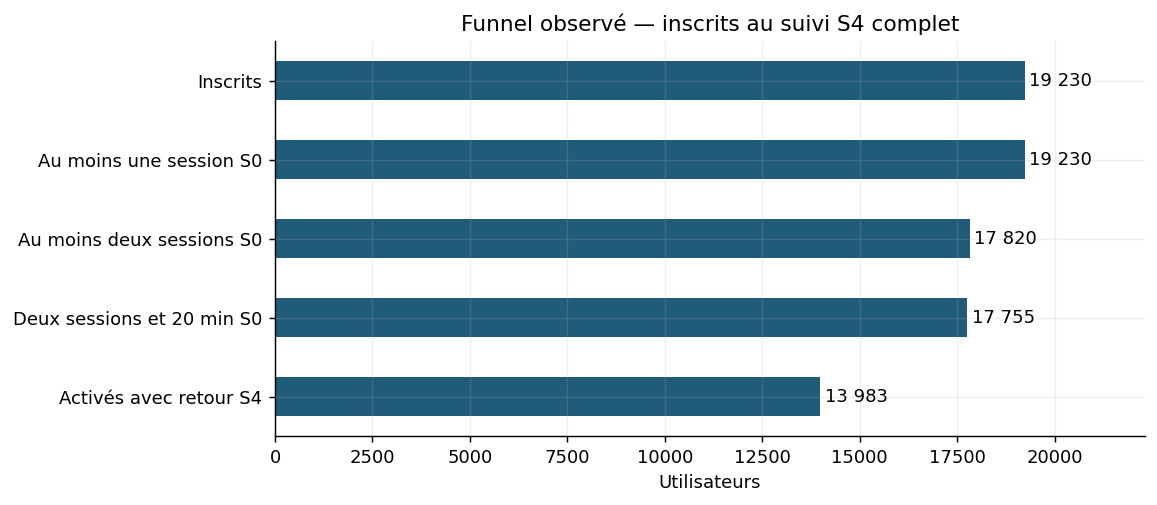

In [12]:
ACTIVATION_MINUTES = 20
activation["activated"] = activation_status(activation, ACTIVATION_MINUTES)
first_week_observed = activation.loc[observable(activation, 0)]
print("Activation sur les inscriptions dont S0 est entièrement observable :")
print("Inscrits :", len(first_week_observed))
print("Activés :", int(first_week_observed["activated"].sum()))
print("Non activés :", int(first_week_observed["activated"].eq(False).sum()))
print("Indéterminés :", int(first_week_observed["activated"].isna().sum()))
print("Taux parmi les cas connus :", round(100 * first_week_observed["activated"].mean(), 2), "%")

funnel_population = activation.loc[observable(activation, 4)].copy()
funnel_population["returned_s4"] = returned(funnel_population, 4)
activated = funnel_population["activated"].fillna(False)
funnel = pd.Series({
    "Inscrits": len(funnel_population),
    "Au moins une session S0": int(funnel_population["sessions"].ge(1).sum()),
    "Au moins deux sessions S0": int(funnel_population["sessions"].ge(2).sum()),
    "Deux sessions et 20 min S0": int(activated.sum()),
    "Activés avec retour S4": int((activated & funnel_population["returned_s4"]).sum()),
})
print("\nFunnel à population constante :")
print(funnel.to_string())
print("Indéterminés exclus du classement d'activation :", int(funnel_population["activated"].isna().sum()))
print("Émissions suivies :", int(funnel_population["shows_followed_week1"].ge(1).sum()), "inscrits en suivent au moins une,", int(funnel_population["shows_followed_week1"].ge(2).sum()), "au moins deux.")
assert first_week_observed["activated"].notna().sum() + first_week_observed["activated"].isna().sum() == len(first_week_observed)
fig, ax = plt.subplots(figsize=(9, 4))
funnel.iloc[::-1].plot.barh(ax=ax, color="#215b7a")
ax.set_xlabel("Utilisateurs")
ax.set_title("Funnel observé — inscrits au suivi S4 complet")
for i, value in enumerate(funnel.iloc[::-1]):
    ax.text(value + 120, i, f"{value:,}".replace(",", " "), va="center")
ax.set_xlim(0, len(funnel_population) * 1.16)
fig.tight_layout()
plt.show()


### Rétention et pertes

Chaque case suit tous les inscrits du mois concerné, y compris ceux qui sont devenus inactifs. Une case reste vide si l'horizon n'est pas entièrement observable pour tous les inscrits de la cohorte. Le retour S1 est de 100 % dans cet extrait ; on ne l'utilise donc pas pour départager les définitions d'activation.

Rétention en %, dénominateur = tous les inscrits de la cohorte :
                    S0             S1             S2             S4             S8            S12
cohorte                                                                                          
2025-01          100.0          100.0           91.8           79.6           63.7           54.3
2025-02          100.0          100.0           93.1           80.7           62.8           52.7
2025-03          100.0          100.0           92.0           80.0           61.3           51.7
2025-04          100.0          100.0           91.4           78.6           61.5           50.2
2025-05          100.0          100.0           91.3           77.6           59.1           48.8
2025-06          100.0          100.0           91.4           78.0           60.3           50.7
2025-07          100.0          100.0           92.1           78.8           61.8           51.6
2025-08          100.0          100.0           90.1 

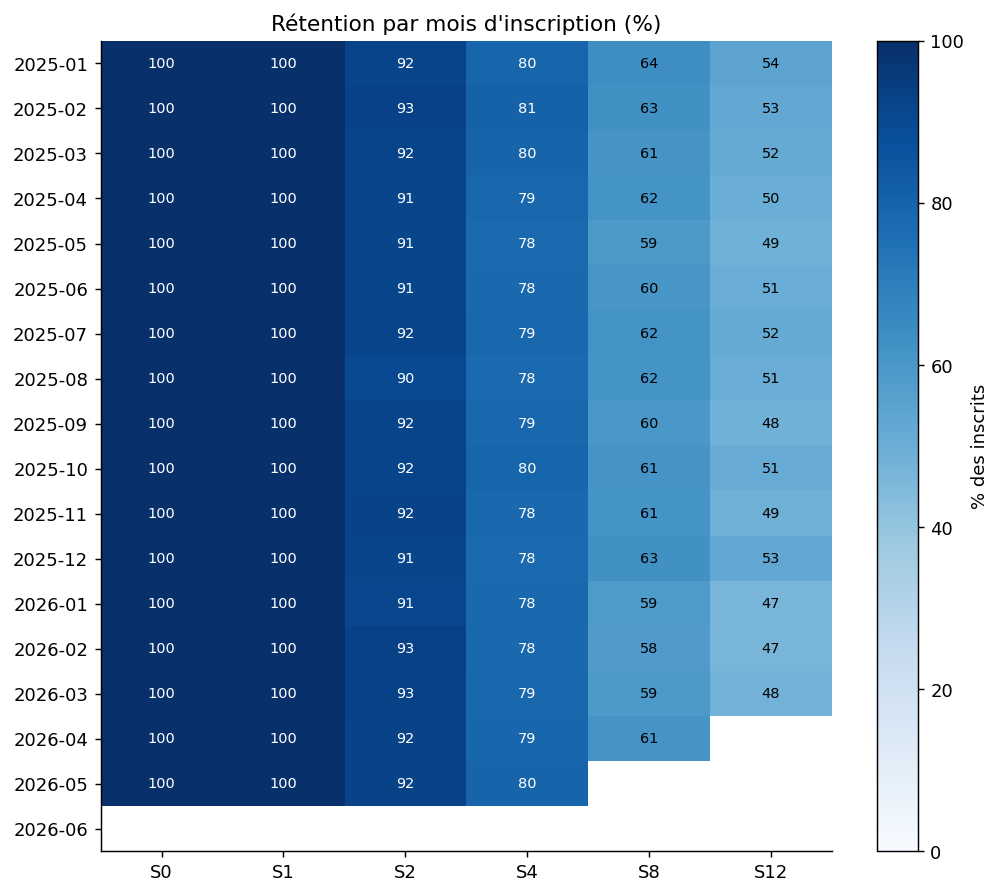

In [13]:
horizons = [0, 1, 2, 4, 8, 12]
retention = pd.DataFrame(index=sorted(users["cohort"].unique()), columns=horizons, dtype=float)
retention.index.name = "cohorte"
for cohort, group in users.groupby("cohort"):
    for age in horizons:
        if observable(group, age).all():
            retention.loc[cohort, age] = 100 * returned(group, age).mean()
print("Rétention en %, dénominateur = tous les inscrits de la cohorte :")
print(retention.round(1).rename(columns=lambda age: f"S{age}").to_string(na_rep="non observable"))
print("\nPertes à horizon observable, tous canaux :")
for age in [1, 4, 8, 12]:
    group = users.loc[observable(users, age)]
    n_returned = int(returned(group, age).sum())
    print(f"S{age} : {n_returned}/{len(group)} actifs ({100*n_returned/len(group):.1f} %), {len(group)-n_returned} sans activité enregistrée.")

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(retention.to_numpy(), vmin=0, vmax=100, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(horizons)), [f"S{x}" for x in horizons])
ax.set_yticks(range(len(retention)), retention.index)
ax.set_title("Rétention par mois d'inscription (%)")
ax.grid(False)
for row in range(len(retention)):
    for col in range(len(horizons)):
        value = retention.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", color="white" if value > 65 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="% des inscrits")
fig.tight_layout()
plt.show()


### Canaux et segments comparables

On compare le retour S4 à la même ancienneté. Pour les canaux, on ajuste aussi sur le mois d'inscription et la plateforme. Pour les plateformes, sur le mois et le canal. Pour l'âge, sur le mois, le canal et la plateforme.

La standardisation applique à chaque groupe la même répartition des strates, pondérée par leurs effectifs regroupés. Seules les strates présentes dans tous les groupes sont conservées. Cela réduit les différences de composition observées ; les comparaisons ne deviennent pas causales pour autant.

acquisition_channel : 34/34 strates communes
                     utilisateurs  retention_brute_pct  retention_ajustee_pct  utilisateurs_strates_communes
acquisition_channel                                                                                         
organic_store                7100                83.34                  83.35                           7100
paid_social                  8262                71.35                  71.35                           8262
podcast_cross_promo          3868                86.25                  86.21                           3868

platform : 51/51 strates communes
          utilisateurs  retention_brute_pct  retention_ajustee_pct  utilisateurs_strates_communes
platform                                                                                         
Android           9644                78.86                  78.89                           9644
iOS               9586                78.69                  78.63               

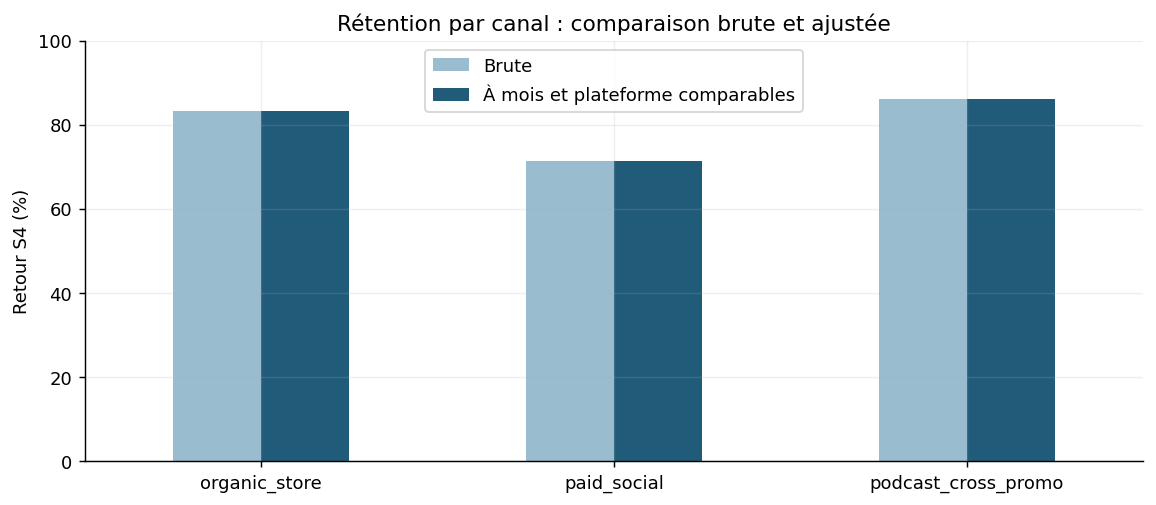

In [14]:
segments = users.loc[observable(users, 4)].copy()
segments["returned_s4"] = returned(segments, 4)

def compare_segments(frame, group_column, strata):
    crude = frame.groupby(group_column)["returned_s4"].agg(["size", "mean"])
    grouped = frame.groupby(strata + [group_column])["returned_s4"].agg(["size", "mean"])
    rates = grouped["mean"].unstack(group_column)
    counts = grouped["size"].unstack(group_column)
    common = rates.notna().all(axis=1)
    weights = counts.loc[common].sum(axis=1)
    weights = weights / weights.sum()
    adjusted = rates.loc[common].mul(weights, axis=0).sum(axis=0)
    result = crude.rename(columns={"size": "utilisateurs", "mean": "retention_brute_pct"})
    result["retention_brute_pct"] *= 100
    result["retention_ajustee_pct"] = adjusted * 100
    result["utilisateurs_strates_communes"] = counts.loc[common].sum(axis=0)
    print(f"{group_column} : {int(common.sum())}/{len(common)} strates communes")
    print(result.round(2).to_string())
    return result

channel_comparison = compare_segments(segments, "acquisition_channel", ["cohort", "platform"])
print()
platform_comparison = compare_segments(segments, "platform", ["cohort", "acquisition_channel"])
print()
age_comparison = compare_segments(segments, "age_bucket", ["cohort", "acquisition_channel", "platform"])
fig, ax = plt.subplots()
channel_comparison[["retention_brute_pct", "retention_ajustee_pct"]].plot.bar(ax=ax, color=["#9abccf", "#215b7a"], rot=0)
ax.set_ylabel("Retour S4 (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.set_title("Rétention par canal : comparaison brute et ajustée")
ax.legend(["Brute", "À mois et plateforme comparables"])
fig.tight_layout()
plt.show()


### Évolution sur les 18 mois

Les graphiques hebdomadaires excluent les semaines du 30 décembre 2024 et du 29 juin 2026, car elles dépassent les bornes de l'extrait. Les revenus sont rattachés à la semaine, sans répartition artificielle entre mois. La croissance de la base active peut venir de l'accumulation des cohortes : on la lit avec la rétention.

La période d'inscription au test push va du 15 janvier au 15 mars 2026, d'après le data pack. Une évolution à cette période ne prouve pas un effet des notifications ; l'analyse randomisée sera faite à l'étape 5.

Inscriptions mensuelles par canal :
acquisition_channel  organic_store  paid_social  podcast_cross_promo
cohort                                                              
2025-01                        300          380                  150
2025-02                        312          391                  157
2025-03                        324          403                  165
2025-04                        337          415                  173
2025-05                        350          427                  182
2025-06                        364          440                  191
2025-07                        379          453                  201
2025-08                        394          467                  211
2025-09                        410          481                  221
2025-10                        426          495                  232
2025-11                        444          510                  244
2025-12                        461          526                  25

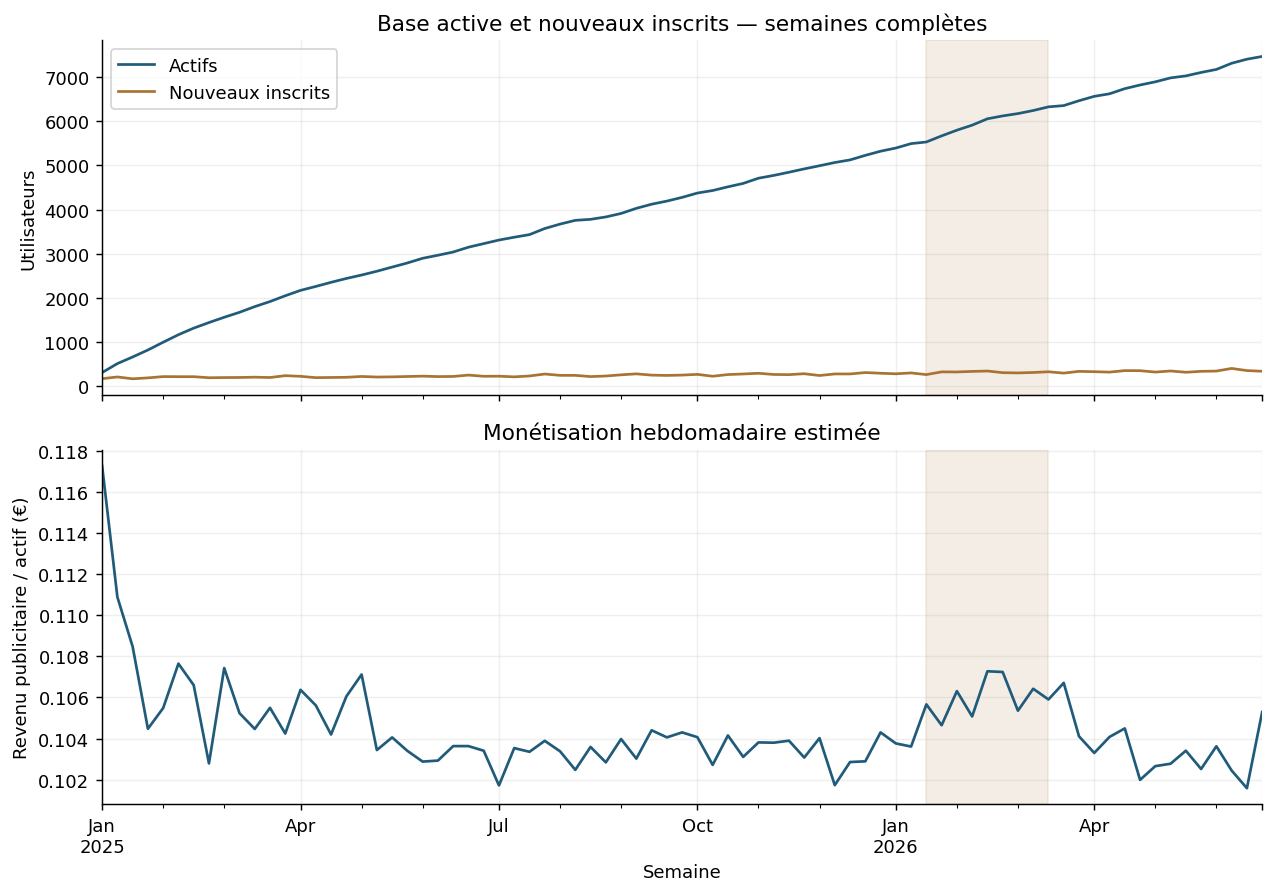

In [15]:
complete_activity = activity.loc[activity["week_start"].ge("2025-01-01") & activity["week_start"].add(pd.Timedelta(days=6)).le(cutoff)]
weekly = complete_activity.groupby("week_start").agg(
    active_users=("user_id", "nunique"), sessions=("sessions", "sum"),
    ad_revenue_eur=("ad_revenue_eur", "sum"), mean_minutes=("listening_minutes", "mean"),
)
weekly["new_users"] = users.groupby("signup_week").size().reindex(weekly.index, fill_value=0)
weekly["revenue_per_active"] = weekly["ad_revenue_eur"] / weekly["active_users"]
monthly_signups = users.groupby(["cohort", "acquisition_channel"]).size().unstack(fill_value=0)
print("Inscriptions mensuelles par canal :")
print(monthly_signups.to_string())
print("\nPremière et dernière semaines complètes :")
print(weekly.iloc[[0, -1]].round(3).to_string())
print("\nRetour S4 par mois d'inscription (cohortes entièrement observables) :")
print(retention[4].dropna().round(2).to_string())

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
weekly[["active_users", "new_users"]].plot(ax=axes[0], color=["#215b7a", "#a87333"])
axes[0].set_title("Base active et nouveaux inscrits — semaines complètes")
axes[0].set_ylabel("Utilisateurs")
axes[0].legend(["Actifs", "Nouveaux inscrits"])
weekly["revenue_per_active"].plot(ax=axes[1], color="#215b7a")
axes[1].set_ylabel("Revenu publicitaire / actif (€)")
axes[1].set_xlabel("Semaine")
axes[1].set_title("Monétisation hebdomadaire estimée")
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-01-15"), pd.Timestamp("2026-03-15"), color="#a87333", alpha=0.12)
fig.tight_layout()
plt.show()


### CAC, revenus cumulés et récupération de l'acquisition

Le CAC est la dépense mensuelle du canal divisée par les inscrits acquis par ce canal. Il n'est calculable que pour `paid_social`. La dépense de mai 2025 est estimée ; son CAC l'est donc aussi. Les autres coûts ne sont ni connus ni supposés nuls.

Le revenu cumulé S0–S11 par inscrit compare les cohortes ayant douze semaines calendaires entièrement observables. Le dénominateur conserve les inactifs. S0 peut être partielle selon le jour d'inscription : ce ne sont pas exactement les 84 premiers jours de vie de chaque utilisateur. Les revenus sont estimés à partir des impressions et du CPM de 9 €.

Ce revenu à horizon fixe n'est pas une LTV totale. La LTV complète exige une extrapolation de la rétention et des revenus futurs ; la LTV en marge exige aussi les coûts. Ces estimations appartiendront au modèle de l'étape 6.

Le payback publicitaire brut est le premier âge hebdomadaire où les revenus cumulés de la cohorte paid couvrent sa dépense d'acquisition. Pour chaque cohorte, on limite le suivi au dernier âge entièrement observable pour tous ses inscrits. « Non atteint » ne signifie pas « jamais atteint ». Ce calcul n'est pas un retour à la rentabilité : les coûts d'exploitation sont absents.

In [16]:
acquisitions = users.groupby(["cohort", "acquisition_channel"]).size().rename("new_users").reset_index()
spend_by_cohort = spend.assign(cohort=spend["month"].dt.to_period("M").astype(str)).rename(columns={"channel": "acquisition_channel"})
cac = acquisitions.merge(spend_by_cohort[["cohort", "acquisition_channel", "spend_eur", "spend_is_estimated"]], on=["cohort", "acquisition_channel"], how="left", validate="one_to_one")
cac["cac_eur"] = cac["spend_eur"] / cac["new_users"]
paid_cac = cac.loc[cac["acquisition_channel"].eq("paid_social")].copy()
print("CAC paid_social par mois (EUR) :")
print(paid_cac[["cohort", "new_users", "spend_eur", "spend_is_estimated", "cac_eur"]].round(3).to_string(index=False))

cohort_end_weeks = users.groupby("cohort")["signup_week"].max()
fully_observed_12 = cohort_end_weeks.index[cohort_end_weeks.add(pd.Timedelta(days=11 * 7 + 6)).le(cutoff)]
eligible_12 = users.loc[users["cohort"].isin(fully_observed_12)].copy()
revenue_12 = activity.loc[activity["cohort"].isin(fully_observed_12) & activity["age_week"].between(0, 11)].groupby("user_id")["ad_revenue_eur"].sum()
eligible_12["revenue_s0_s11_eur"] = eligible_12["user_id"].map(revenue_12).fillna(0)
cohort_economics = eligible_12.groupby(["cohort", "acquisition_channel"]).agg(users=("user_id", "size"), revenue_s0_s11_eur=("revenue_s0_s11_eur", "mean")).reset_index()
cohort_economics = cohort_economics.merge(cac[["cohort", "acquisition_channel", "cac_eur", "spend_is_estimated"]], on=["cohort", "acquisition_channel"], validate="one_to_one")
print("\nRevenu publicitaire S0-S11 par inscrit et par cohorte (EUR) :")
print(cohort_economics.pivot(index="cohort", columns="acquisition_channel", values="revenue_s0_s11_eur").round(3).to_string())

channel_economics = eligible_12.groupby("acquisition_channel").agg(users=("user_id", "size"), revenue_s0_s11_eur=("revenue_s0_s11_eur", "mean"))
eligible_paid_cac = paid_cac.loc[paid_cac["cohort"].isin(fully_observed_12)]
channel_economics["cac_eur"] = float("nan")
channel_economics.loc["paid_social", "cac_eur"] = eligible_paid_cac["spend_eur"].sum() / eligible_paid_cac["new_users"].sum()
channel_economics["revenue_12w_over_cac"] = channel_economics["revenue_s0_s11_eur"] / channel_economics["cac_eur"]
print("\nSynthèse sur les mêmes cohortes entièrement observables à 12 semaines :")
print(channel_economics.round(3).to_string(na_rep="inconnu"))

payback_rows = []
for row in paid_cac.itertuples(index=False):
    max_age = (int((cutoff - cohort_end_weeks.loc[row.cohort]).days) - 6) // 7
    if max_age < 0:
        payback_rows.append({"cohort": row.cohort, "semaines_observees": 0, "payback_semaines": float("nan"), "statut": "suivi incomplet", "depense_estimee": row.spend_is_estimated, "revenu_sur_depense": float("nan")})
        continue
    cohort_revenue = activity.loc[activity["cohort"].eq(row.cohort) & activity["acquisition_channel"].eq("paid_social") & activity["age_week"].between(0, max_age)]
    cumulative = cohort_revenue.groupby("age_week")["ad_revenue_eur"].sum().reindex(range(max_age + 1), fill_value=0).cumsum()
    recovered = cumulative.index[cumulative.ge(row.spend_eur)]
    payback_rows.append({"cohort": row.cohort, "semaines_observees": max_age + 1, "payback_semaines": int(recovered[0]) + 1 if len(recovered) else float("nan"), "statut": "atteint" if len(recovered) else "non atteint pendant le suivi", "depense_estimee": row.spend_is_estimated, "revenu_sur_depense": cumulative.iloc[-1] / row.spend_eur})
payback = pd.DataFrame(payback_rows)
print("\nRécupération publicitaire brute par cohorte paid_social :")
print(payback.round(3).to_string(index=False, na_rep="—"))
print("\nSensibilité : CAC agrégé à 12 semaines hors mai 2025 estimé :", round(eligible_paid_cac.loc[eligible_paid_cac["spend_is_estimated"].eq(False), "spend_eur"].sum() / eligible_paid_cac.loc[eligible_paid_cac["spend_is_estimated"].eq(False), "new_users"].sum(), 3), "EUR")
assert len(eligible_12) == cohort_economics["users"].sum()
assert channel_economics.loc[["organic_store", "podcast_cross_promo"], "cac_eur"].isna().all()
assert (payback["payback_semaines"].dropna() <= payback.loc[payback["payback_semaines"].notna(), "semaines_observees"]).all()


CAC paid_social par mois (EUR) :
 cohort  new_users  spend_eur spend_is_estimated  cac_eur
2025-01        380      990.0              False    2.605
2025-02        391     1020.0              False    2.609
2025-03        403     1050.0              False    2.605
2025-04        415     1080.0              False    2.602
2025-05        427     1115.0               True    2.611
2025-06        440     1150.0              False    2.614
2025-07        453     1180.0              False    2.605
2025-08        467     1220.0              False    2.612
2025-09        481     1250.0              False    2.599
2025-10        495     1290.0              False    2.606
2025-11        510     1330.0              False    2.608
2025-12        526     1370.0              False    2.605
2026-01        541     1410.0              False    2.606
2026-02        558     1450.0              False    2.599
2026-03        574     1490.0              False    2.596
2026-04        592     1540.0          

### North Star Metric

On retient les minutes totales d'écoute hebdomadaires. Elles représentent la quantité de contenu consommée et combinent audience et intensité d'usage. Les sessions seules peuvent augmenter sans écoute. Le temps d'écoute reste une approximation de la valeur, pas une preuve de satisfaction.

On l'accompagne du nombre d'actifs, de la rétention, de la moyenne et de la médiane d'écoute, et des notifications reçues par actif. Le total peut croître uniquement parce que l'audience grandit ; la moyenne peut augmenter si les petits auditeurs partent. On lit donc les métriques ensemble.

Le total porte sur les durées connues et sous-estime potentiellement l'écoute réelle. On affiche la couverture au lieu de traiter les durées manquantes comme zéro. Les moyennes et médianes portent également sur les durées connues. Seules les semaines complètes sont comparées.

Première et dernière semaines complètes :
            listening_minutes  mean_known_minutes  median_known_minutes  active_users  engaged_users  engagement_unknown  known_durations  push_received  coverage_pct  push_per_active
week_start                                                                                                                                                                             
2025-01-06            28618.0               91.72                 81.85           312            277                   0              312           1244        100.00             3.99
2026-06-22           618332.1               82.92                 70.60          7468           6391                  11             7457          40299         99.85             5.40

Couverture minimale des durées connues : 99.61 %


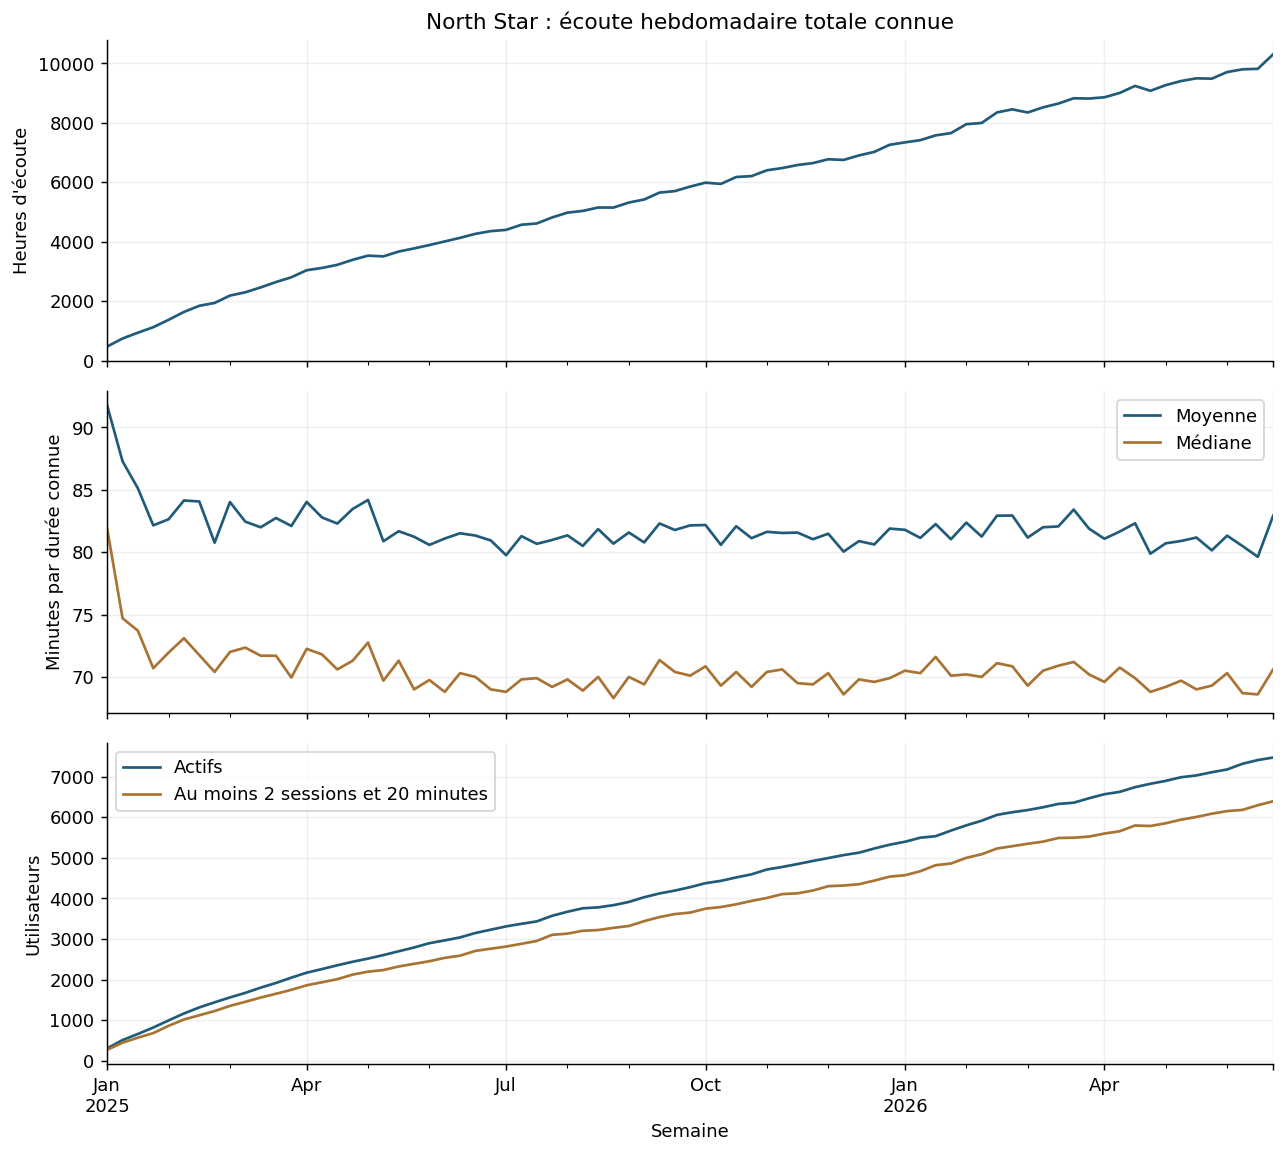

In [17]:
complete_activity = complete_activity.copy()
complete_activity["engaged"] = complete_activity["sessions"].ge(2) & complete_activity["listening_minutes"].ge(ACTIVATION_MINUTES)
complete_activity["engagement_unknown"] = complete_activity["sessions"].ge(2) & complete_activity["listening_minutes"].isna()
north_star = complete_activity.groupby("week_start").agg(
    listening_minutes=("listening_minutes", lambda s: s.sum(min_count=1)),
    mean_known_minutes=("listening_minutes", "mean"), median_known_minutes=("listening_minutes", "median"),
    active_users=("user_id", "nunique"), engaged_users=("engaged", "sum"),
    engagement_unknown=("engagement_unknown", "sum"), known_durations=("listening_minutes", "count"),
    push_received=("push_notifications_received", "sum"),
)
north_star["coverage_pct"] = 100 * north_star["known_durations"] / north_star["active_users"]
north_star["push_per_active"] = north_star["push_received"] / north_star["active_users"]
print("Première et dernière semaines complètes :")
print(north_star.iloc[[0, -1]].round(2).to_string())
print("\nCouverture minimale des durées connues :", round(north_star["coverage_pct"].min(), 2), "%")

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
north_star["listening_minutes"].div(60).plot(ax=axes[0], color="#215b7a")
axes[0].set_title("North Star : écoute hebdomadaire totale connue")
axes[0].set_ylabel("Heures d'écoute")
north_star[["mean_known_minutes", "median_known_minutes"]].plot(ax=axes[1], color=["#215b7a", "#a87333"])
axes[1].set_ylabel("Minutes par durée connue")
axes[1].legend(["Moyenne", "Médiane"])
north_star[["active_users", "engaged_users"]].plot(ax=axes[2], color=["#215b7a", "#a87333"])
axes[2].set_ylabel("Utilisateurs")
axes[2].set_xlabel("Semaine")
axes[2].legend(["Actifs", "Au moins 2 sessions et 20 minutes"])
fig.tight_layout()
plt.show()
assert north_star["coverage_pct"].between(0, 100).all()
assert (north_star["engaged_users"] + north_star["engagement_unknown"] <= north_star["active_users"]).all()


### Ce que l'on retient

- La base active et les inscriptions augmentent. Les cohortes perdent toutefois des utilisateurs avec l'ancienneté : la hausse de la base ne prouve pas une amélioration de la rétention.
- Le retour S4 de paid_social est plus faible que celui des deux autres canaux, même à mois d'inscription et plateforme comparables. Ce constat ne prouve pas que le canal cause la différence.
- Les différences entre plateformes sont faibles. Une partie des écarts bruts entre âges vient de la composition des groupes.
- L'activation à deux sessions et 20 minutes est une convention de mesure. Elle ne prédit pas ici un meilleur retour S4 que les autres seuils testés.
- Les minutes totales connues augmentent avec l'audience, sans hausse comparable de l'écoute moyenne par actif. Les notifications seront jugées aussi sur l'écoute et la rétention, pas seulement sur les ouvertures.
- Sur les cohortes entièrement observables à douze semaines, paid_social génère environ 0,84 € de revenu publicitaire par inscrit pour un CAC de 2,61 €, soit 32,4 % du CAC récupéré à cet horizon. Aucun payback brut n’est atteint sur les horizons communs observés ; cela ne prouve pas qu’il ne sera jamais atteint. La LTV complète et la rentabilité restent à estimer avec des hypothèses explicites.

L'étape 5 évaluera le test randomisé de notifications. Le diagnostic présent ne suffit pas à attribuer les évolutions aux notifications ni à recommander leur généralisation.
